Mounted at /content/drive
Video exists: True
cap opened: True
Final FPS: 29.19782030160943
Frame count: 512
Duration (s): 17.535555555555554
Saved frames: 35
Synthetic GPS log saved to: /content/drive/MyDrive/uav_project/synthetic_gps_log.csv


  0%|          | 0/35 [00:00<?, ?it/s]

Frame-level metrics saved to: /content/drive/MyDrive/uav_project/frame_level_metrics.csv


  0%|          | 0/35 [00:00<?, ?it/s]

Saved frame previews: 86


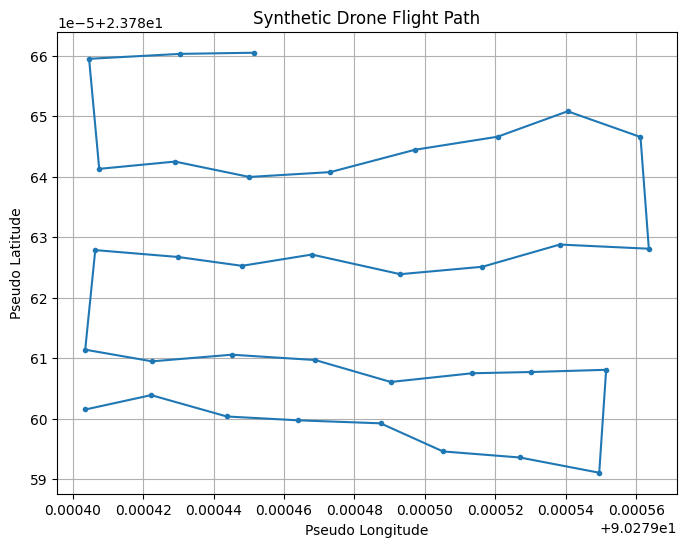

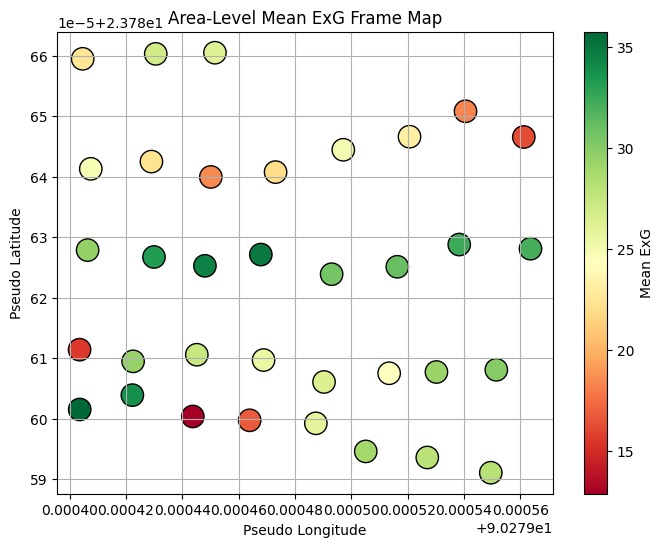

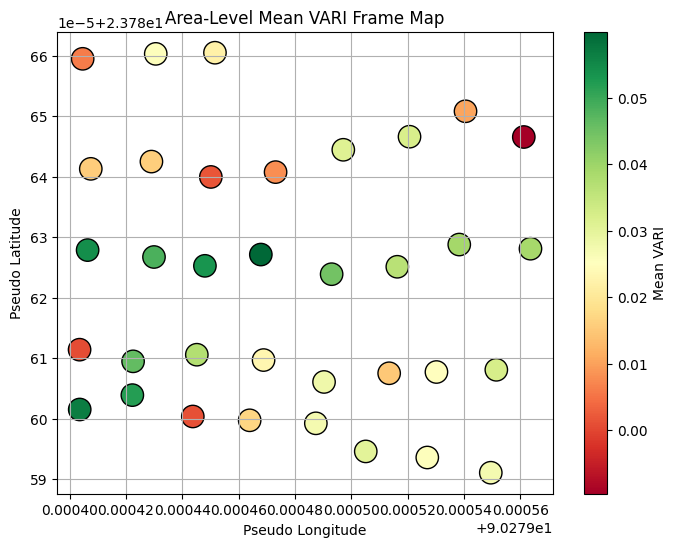

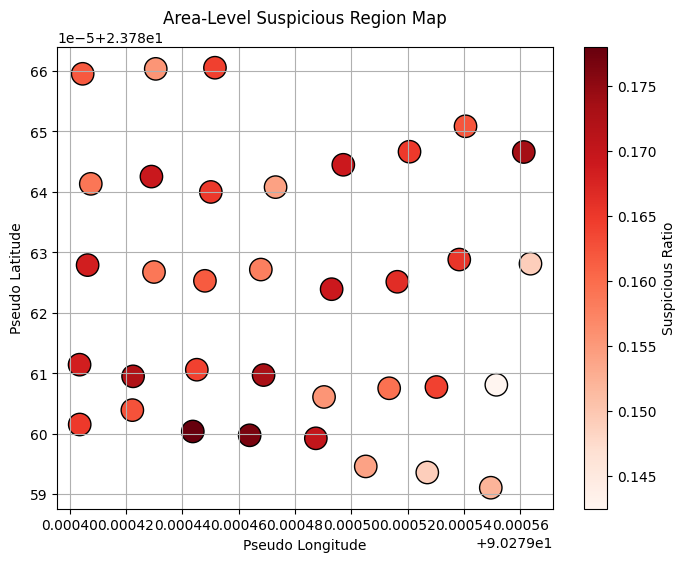

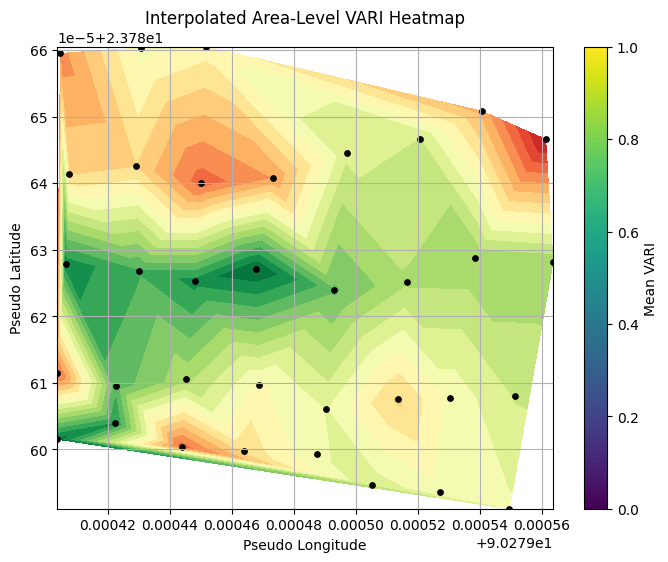

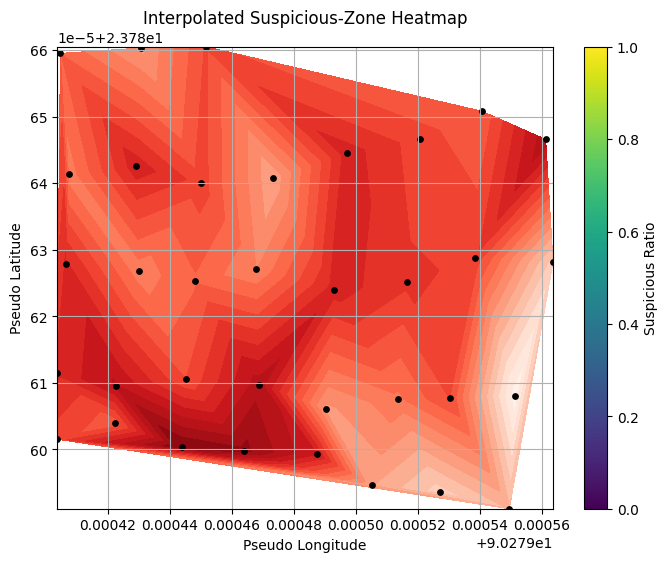

  0%|          | 0/35 [00:00<?, ?it/s]

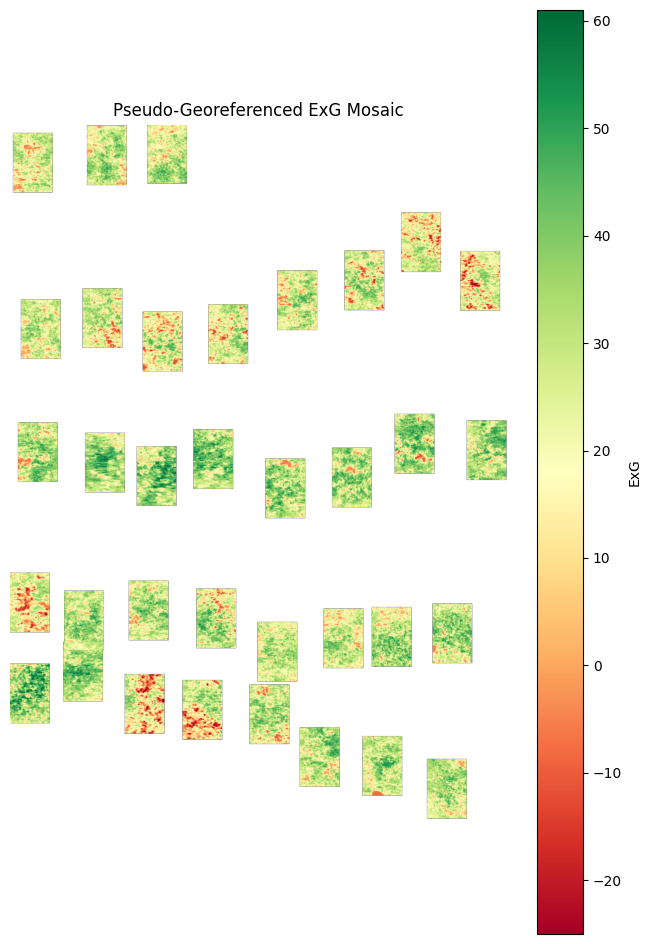

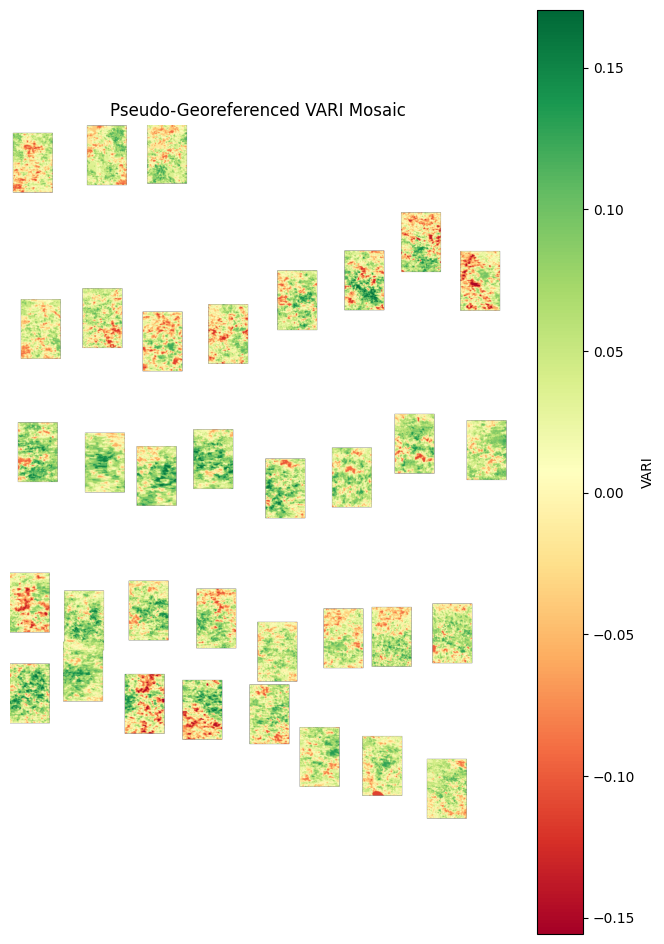

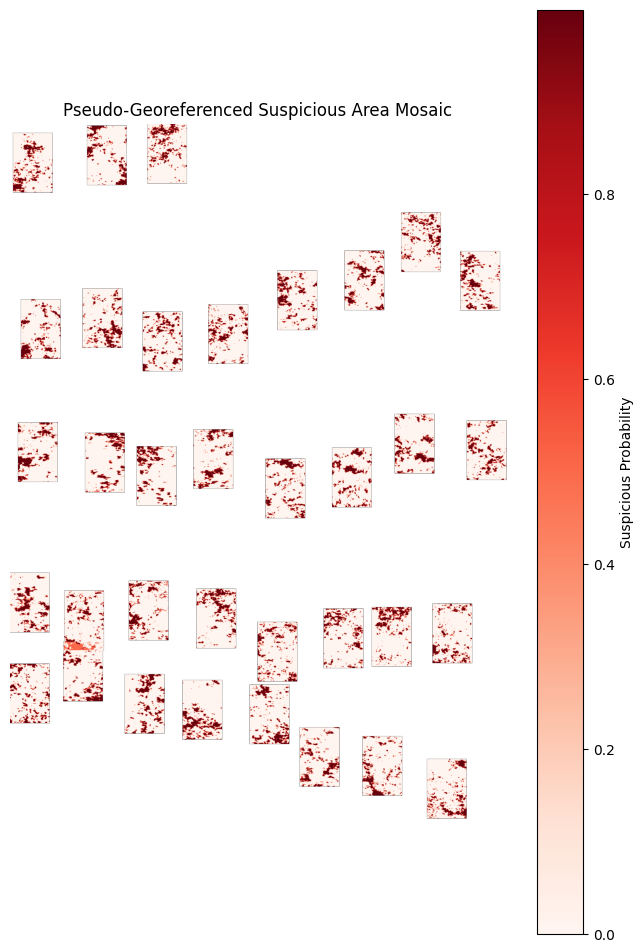

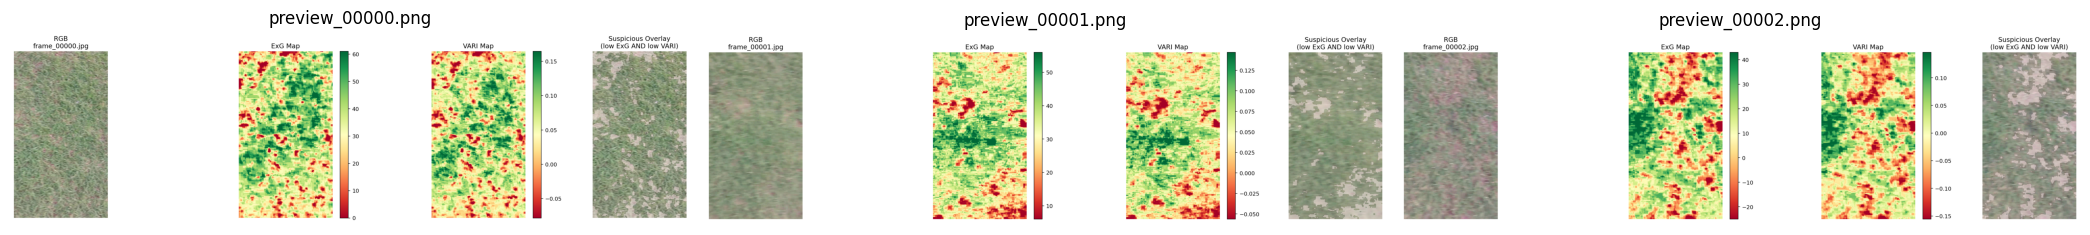


Done.
Synthetic GPS log: /content/drive/MyDrive/uav_project/synthetic_gps_log.csv
Frame metrics: /content/drive/MyDrive/uav_project/frame_level_metrics.csv
Frame previews folder: /content/drive/MyDrive/uav_project/frame_level_outputs
Area outputs folder: /content/drive/MyDrive/uav_project/area_level_outputs
                  metric      value
0             num_frames  35.000000
1       mean_of_mean_exg  26.352708
2      mean_of_mean_vari   0.027954
3   max_suspicious_ratio   0.178003
4  mean_suspicious_ratio   0.162908


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import cv2
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

VIDEO_PATH = Path("/content/drive/MyDrive/uav_project/drone_video.mp4")
BASE_DIR = Path("/content/drive/MyDrive/uav_project")
FRAME_DIR = BASE_DIR / "extracted_frames"
FRAME_PREVIEW_DIR = BASE_DIR / "frame_level_outputs"
AREA_DIR = BASE_DIR / "area_level_outputs"

FRAME_DIR.mkdir(parents=True, exist_ok=True)
FRAME_PREVIEW_DIR.mkdir(parents=True, exist_ok=True)
AREA_DIR.mkdir(parents=True, exist_ok=True)

print("Video exists:", VIDEO_PATH.exists())

cap = cv2.VideoCapture(str(VIDEO_PATH))
print("cap opened:", cap.isOpened())

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if not cap.isOpened():
    raise ValueError("Video could not be opened. Check the file path.")

if fps is None or fps <= 0:
    print("FPS could not be read. Setting fallback FPS = 30")
    fps = 30.0

duration = frame_count / fps if frame_count > 0 else 0
print("Final FPS:", fps)
print("Frame count:", frame_count)
print("Duration (s):", duration)
cap.release()

interval_sec = 0.5
cap = cv2.VideoCapture(str(VIDEO_PATH))
step = max(1, int(round(fps * interval_sec)))

saved = 0
idx = 0
frame_rows = []

while True:
    ret, frame = cap.read()
    if not ret:
        break

    if idx % step == 0:
        frame_name = f"frame_{saved:05d}.jpg"
        frame_path = FRAME_DIR / frame_name
        cv2.imwrite(str(frame_path), frame)

        timestamp_sec = idx / fps
        frame_rows.append({
            "frame_idx_video": idx,
            "frame_id": saved,
            "frame_name": frame_name,
            "frame_path": str(frame_path),
            "timestamp_sec": timestamp_sec
        })
        saved += 1

    idx += 1

cap.release()

frames_df = pd.DataFrame(frame_rows)
print("Saved frames:", len(frames_df))

np.random.seed(42)

n = len(frames_df)
start_lat = 23.780600
start_lon = 90.279400
row_len = 8
n_rows = math.ceil(n / row_len)

base_d_lat = 0.000018
base_d_lon = 0.000022

rows = []
k = 0
lat_drift = 0.0
lon_drift = 0.0

for r in range(n_rows):
    col_order = list(range(row_len)) if r % 2 == 0 else list(range(row_len - 1, -1, -1))

    for c in col_order:
        if k >= n:
            break

        t = frames_df.loc[k, "timestamp_sec"]

        lat_base = start_lat + r * base_d_lat
        lon_base = start_lon + c * base_d_lon

        lat_drift += np.random.normal(0, 0.0000015)
        lon_drift += np.random.normal(0, 0.0000015)

        wobble_lat = 0.0000025 * np.sin(2 * np.pi * k / 11.0)
        wobble_lon = 0.0000020 * np.cos(2 * np.pi * k / 13.0)

        gps_noise_lat = np.random.normal(0, 0.0000012)
        gps_noise_lon = np.random.normal(0, 0.0000012)

        lat = lat_base + lat_drift + wobble_lat + gps_noise_lat
        lon = lon_base + lon_drift + wobble_lon + gps_noise_lon

        altitude_m = 28 + 1.2 * np.sin(2 * np.pi * k / 9.0) + np.random.normal(0, 0.25)
        heading_deg = (90 if r % 2 == 0 else 270) + 5 * np.sin(2 * np.pi * k / 7.0) + np.random.normal(0, 1.2)
        speed_mps = 2.5 + 0.3 * np.sin(2 * np.pi * k / 8.0) + np.random.normal(0, 0.08)

        rows.append({
            "frame_id": int(frames_df.loc[k, "frame_id"]),
            "frame_name": frames_df.loc[k, "frame_name"],
            "frame_path": frames_df.loc[k, "frame_path"],
            "timestamp_sec": float(t),
            "lat": lat,
            "lon": lon,
            "altitude_m": altitude_m,
            "heading_deg": heading_deg,
            "speed_mps": speed_mps,
            "survey_row": r,
            "survey_col": c
        })
        k += 1

gps_df = pd.DataFrame(rows)
gps_csv_path = BASE_DIR / "synthetic_gps_log.csv"
gps_df.to_csv(gps_csv_path, index=False)
print("Synthetic GPS log saved to:", gps_csv_path)

def compute_exg_vari(frame_path):
    img = np.array(Image.open(frame_path).convert("RGB")).astype(np.float32)
    R = img[:, :, 0]
    G = img[:, :, 1]
    B = img[:, :, 2]
    exg = 2 * G - R - B
    vari = (G - R) / (G + R - B + 1e-6)
    return img, exg, vari

def robust_stats(x, low_q=2, high_q=98):
    lo = np.percentile(x, low_q)
    hi = np.percentile(x, high_q)
    x_clip = np.clip(x, lo, hi)
    return {
        "mean": float(np.mean(x_clip)),
        "std": float(np.std(x_clip)),
        "min_clip": float(np.min(x_clip)),
        "max_clip": float(np.max(x_clip)),
        "lo": float(lo),
        "hi": float(hi)
    }

def clip_map(x, low_q=2, high_q=98):
    lo = np.percentile(x, low_q)
    hi = np.percentile(x, high_q)
    return np.clip(x, lo, hi)

feature_rows = []

for _, row in tqdm(gps_df.iterrows(), total=len(gps_df)):
    img, exg, vari = compute_exg_vari(row["frame_path"])

    exg_stats = robust_stats(exg)
    vari_stats = robust_stats(vari)

    exg_low_thresh = np.percentile(exg, 20)
    vari_low_thresh = np.percentile(vari, 20)

    low_exg_mask = (exg < exg_low_thresh).astype(np.uint8)
    low_vari_mask = (vari < vari_low_thresh).astype(np.uint8)

    kernel = np.ones((5, 5), np.uint8)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_OPEN, kernel)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_CLOSE, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_OPEN, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_CLOSE, kernel)

    suspicious_mask = (low_exg_mask & low_vari_mask).astype(bool)

    low_exg_ratio = float(np.mean(low_exg_mask))
    low_vari_ratio = float(np.mean(low_vari_mask))
    suspicious_ratio = float(np.mean(suspicious_mask))

    feature_rows.append({
        "frame_id": row["frame_id"],
        "frame_name": row["frame_name"],
        "frame_path": row["frame_path"],
        "timestamp_sec": row["timestamp_sec"],
        "lat": row["lat"],
        "lon": row["lon"],
        "altitude_m": row["altitude_m"],
        "heading_deg": row["heading_deg"],
        "speed_mps": row["speed_mps"],
        "survey_row": row["survey_row"],
        "survey_col": row["survey_col"],
        "mean_exg": exg_stats["mean"],
        "std_exg": exg_stats["std"],
        "mean_vari": vari_stats["mean"],
        "std_vari": vari_stats["std"],
        "low_exg_ratio": low_exg_ratio,
        "low_vari_ratio": low_vari_ratio,
        "suspicious_ratio": suspicious_ratio
    })

index_df = pd.DataFrame(feature_rows)
metrics_csv_path = BASE_DIR / "frame_level_metrics.csv"
index_df.to_csv(metrics_csv_path, index=False)
print("Frame-level metrics saved to:", metrics_csv_path)

for _, row in tqdm(index_df.iterrows(), total=len(index_df)):
    img, exg, vari = compute_exg_vari(row["frame_path"])

    exg_map = clip_map(exg)
    vari_map = clip_map(vari)

    exg_low_thresh = np.percentile(exg, 20)
    vari_low_thresh = np.percentile(vari, 20)

    low_exg_mask = (exg < exg_low_thresh).astype(np.uint8)
    low_vari_mask = (vari < vari_low_thresh).astype(np.uint8)

    kernel = np.ones((5, 5), np.uint8)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_OPEN, kernel)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_CLOSE, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_OPEN, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_CLOSE, kernel)

    suspicious_mask = (low_exg_mask & low_vari_mask).astype(bool)

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(img.astype(np.uint8))
    axes[0].set_title(f"RGB\n{row['frame_name']}")
    axes[0].axis("off")

    im1 = axes[1].imshow(exg_map, cmap="RdYlGn")
    axes[1].set_title("ExG Map")
    axes[1].axis("off")
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

    im2 = axes[2].imshow(vari_map, cmap="RdYlGn")
    axes[2].set_title("VARI Map")
    axes[2].axis("off")
    plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    axes[3].imshow(img.astype(np.uint8))
    axes[3].imshow(np.where(suspicious_mask, 1.0, np.nan), cmap="Reds", alpha=0.45)
    axes[3].set_title("Suspicious Overlay\n(low ExG AND low VARI)")
    axes[3].axis("off")

    plt.tight_layout()
    out_path = FRAME_PREVIEW_DIR / f"preview_{int(row['frame_id']):05d}.png"
    plt.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.close()

preview_files = sorted(FRAME_PREVIEW_DIR.glob("*.png"))
print("Saved frame previews:", len(preview_files))

plt.figure(figsize=(8, 6))
plt.plot(gps_df["lon"], gps_df["lat"], "-o", markersize=3)
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Synthetic Drone Flight Path")
plt.grid(True)
plt.savefig(AREA_DIR / "synthetic_flight_path.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
sc = plt.scatter(index_df["lon"], index_df["lat"], c=index_df["mean_exg"], cmap="RdYlGn", s=260, edgecolors="black")
plt.colorbar(sc, label="Mean ExG")
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Area-Level Mean ExG Frame Map")
plt.grid(True)
plt.savefig(AREA_DIR / "area_mean_exg_scatter.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
sc = plt.scatter(index_df["lon"], index_df["lat"], c=index_df["mean_vari"], cmap="RdYlGn", s=260, edgecolors="black")
plt.colorbar(sc, label="Mean VARI")
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Area-Level Mean VARI Frame Map")
plt.grid(True)
plt.savefig(AREA_DIR / "area_mean_vari_scatter.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
sc = plt.scatter(index_df["lon"], index_df["lat"], c=index_df["suspicious_ratio"], cmap="Reds", s=260, edgecolors="black")
plt.colorbar(sc, label="Suspicious Ratio")
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Area-Level Suspicious Region Map")
plt.grid(True)
plt.savefig(AREA_DIR / "area_suspicious_ratio_scatter.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.tricontourf(index_df["lon"], index_df["lat"], index_df["mean_vari"], levels=20, cmap="RdYlGn")
plt.scatter(index_df["lon"], index_df["lat"], c="black", s=15)
plt.colorbar(label="Mean VARI")
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Interpolated Area-Level VARI Heatmap")
plt.grid(True)
plt.savefig(AREA_DIR / "area_vari_interpolated.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.tricontourf(index_df["lon"], index_df["lat"], index_df["suspicious_ratio"], levels=20, cmap="Reds")
plt.scatter(index_df["lon"], index_df["lat"], c="black", s=15)
plt.colorbar(label="Suspicious Ratio")
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Interpolated Suspicious-Zone Heatmap")
plt.grid(True)
plt.savefig(AREA_DIR / "area_suspicious_interpolated.png", dpi=220, bbox_inches="tight")
plt.show()

tile_h = 120
tile_w = 80

lats = index_df["lat"].values
lons = index_df["lon"].values

lat_min, lat_max = lats.min(), lats.max()
lon_min, lon_max = lons.min(), lons.max()

canvas_h = 1400
canvas_w = 1000

sum_exg = np.zeros((canvas_h, canvas_w), dtype=np.float32)
sum_vari = np.zeros((canvas_h, canvas_w), dtype=np.float32)
sum_susp = np.zeros((canvas_h, canvas_w), dtype=np.float32)
count_canvas = np.zeros((canvas_h, canvas_w), dtype=np.float32)

for _, row in tqdm(index_df.iterrows(), total=len(index_df)):
    _, exg, vari = compute_exg_vari(row["frame_path"])

    exg_lo, exg_hi = np.percentile(exg, 2), np.percentile(exg, 98)
    vari_lo, vari_hi = np.percentile(vari, 2), np.percentile(vari, 98)

    exg_small = cv2.resize(np.clip(exg, exg_lo, exg_hi), (tile_w, tile_h), interpolation=cv2.INTER_AREA)
    vari_small = cv2.resize(np.clip(vari, vari_lo, vari_hi), (tile_w, tile_h), interpolation=cv2.INTER_AREA)

    exg_low_thresh = np.percentile(exg, 20)
    vari_low_thresh = np.percentile(vari, 20)

    low_exg_mask = (exg < exg_low_thresh).astype(np.uint8)
    low_vari_mask = (vari < vari_low_thresh).astype(np.uint8)

    kernel = np.ones((5, 5), np.uint8)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_OPEN, kernel)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_CLOSE, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_OPEN, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_CLOSE, kernel)

    suspicious = (low_exg_mask & low_vari_mask).astype(np.float32)
    suspicious_small = cv2.resize(suspicious, (tile_w, tile_h), interpolation=cv2.INTER_AREA)

    x = int((row["lon"] - lon_min) / (lon_max - lon_min + 1e-9) * (canvas_w - tile_w))
    y = int((lat_max - row["lat"]) / (lat_max - lat_min + 1e-9) * (canvas_h - tile_h))

    sum_exg[y:y+tile_h, x:x+tile_w] += exg_small
    sum_vari[y:y+tile_h, x:x+tile_w] += vari_small
    sum_susp[y:y+tile_h, x:x+tile_w] += suspicious_small
    count_canvas[y:y+tile_h, x:x+tile_w] += 1

mosaic_exg = sum_exg / (count_canvas + 1e-6)
mosaic_vari = sum_vari / (count_canvas + 1e-6)
mosaic_susp = sum_susp / (count_canvas + 1e-6)

mosaic_exg[count_canvas == 0] = np.nan
mosaic_vari[count_canvas == 0] = np.nan
mosaic_susp[count_canvas == 0] = np.nan

plt.figure(figsize=(8, 12))
plt.imshow(mosaic_exg, cmap="RdYlGn")
plt.colorbar(label="ExG")
plt.title("Pseudo-Georeferenced ExG Mosaic")
plt.axis("off")
plt.savefig(AREA_DIR / "mosaic_exg.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 12))
plt.imshow(mosaic_vari, cmap="RdYlGn")
plt.colorbar(label="VARI")
plt.title("Pseudo-Georeferenced VARI Mosaic")
plt.axis("off")
plt.savefig(AREA_DIR / "mosaic_vari.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 12))
plt.imshow(mosaic_susp, cmap="Reds")
plt.colorbar(label="Suspicious Probability")
plt.title("Pseudo-Georeferenced Suspicious Area Mosaic")
plt.axis("off")
plt.savefig(AREA_DIR / "mosaic_suspicious.png", dpi=220, bbox_inches="tight")
plt.show()

n_show = min(3, len(preview_files))
fig, axes = plt.subplots(1, n_show, figsize=(7 * n_show, 6))
if n_show == 1:
    axes = [axes]

for ax, f in zip(axes, preview_files[:n_show]):
    img_prev = np.array(Image.open(f))
    ax.imshow(img_prev)
    ax.set_title(f.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

summary_df = pd.DataFrame({
    "metric": [
        "num_frames",
        "mean_of_mean_exg",
        "mean_of_mean_vari",
        "max_suspicious_ratio",
        "mean_suspicious_ratio"
    ],
    "value": [
        len(index_df),
        index_df["mean_exg"].mean(),
        index_df["mean_vari"].mean(),
        index_df["suspicious_ratio"].max(),
        index_df["suspicious_ratio"].mean()
    ]
})

summary_path = AREA_DIR / "area_summary_stats.csv"
summary_df.to_csv(summary_path, index=False)

print("\nDone.")
print("Synthetic GPS log:", gps_csv_path)
print("Frame metrics:", metrics_csv_path)
print("Frame previews folder:", FRAME_PREVIEW_DIR)
print("Area outputs folder:", AREA_DIR)
print(summary_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Video exists: True
cap opened: True
Final FPS: 29.19782030160943
Frame count: 512
Duration (s): 17.535555555555554
Saved frames: 86
Synthetic GPS log saved to: /content/drive/MyDrive/uav_project/synthetic_gps_log.csv


  0%|          | 0/86 [00:00<?, ?it/s]

Frame-level metrics saved to: /content/drive/MyDrive/uav_project/frame_level_metrics.csv


  0%|          | 0/86 [00:00<?, ?it/s]

Saved frame previews: 86


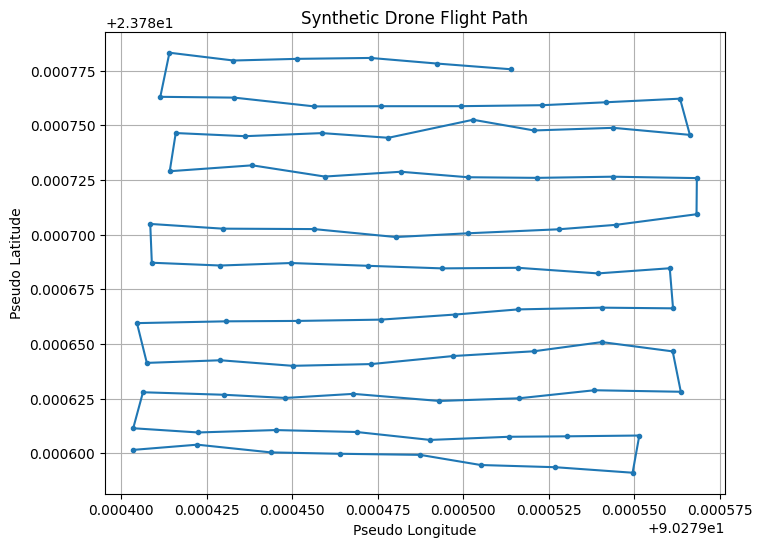

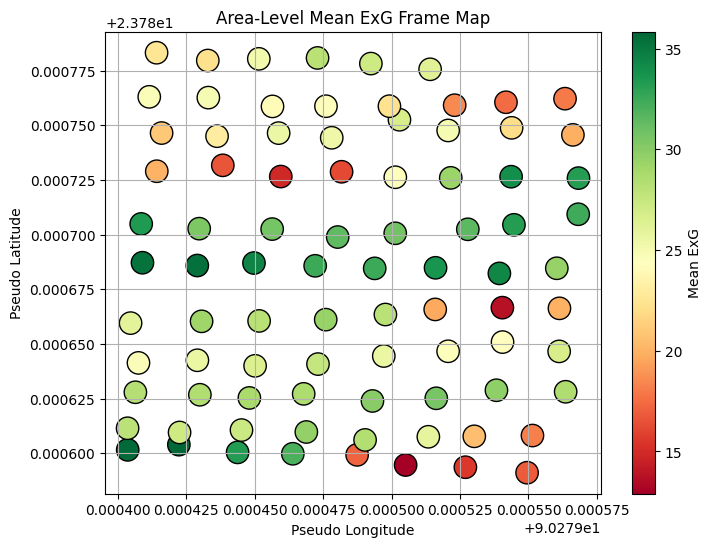

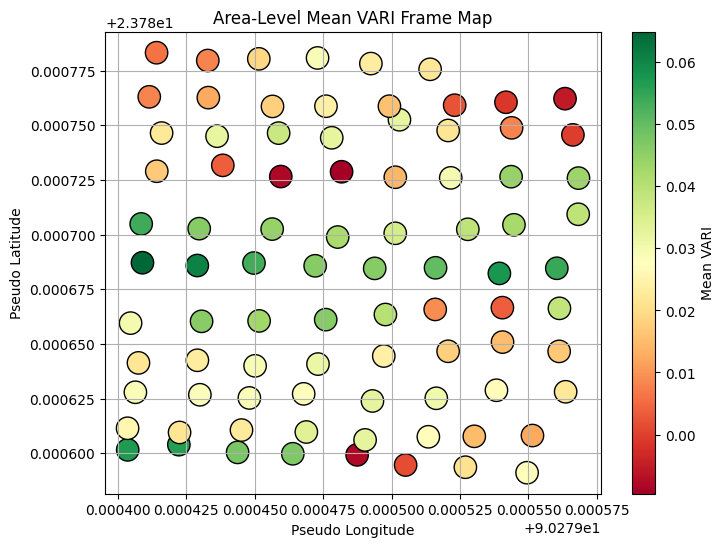

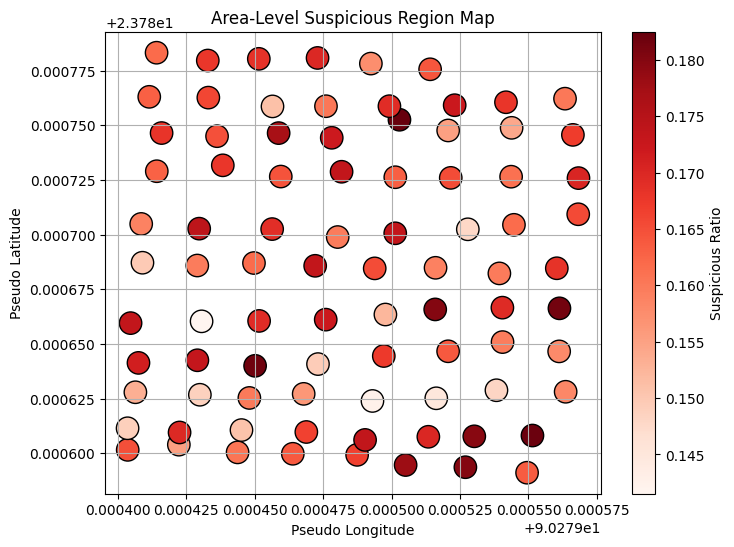

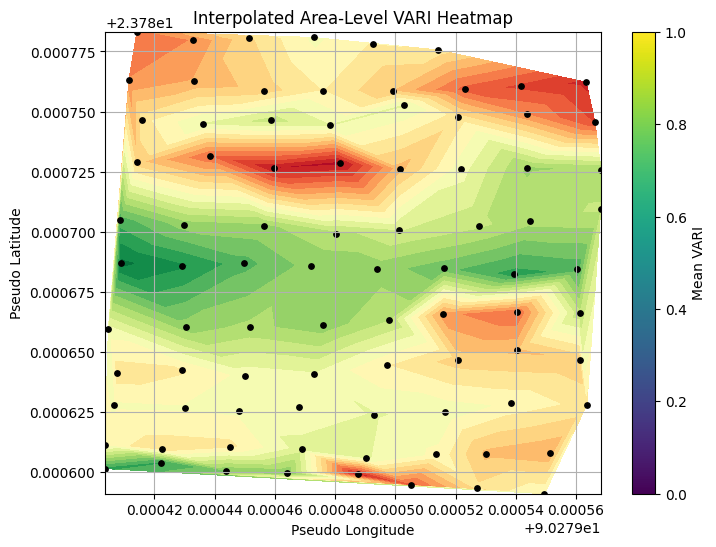

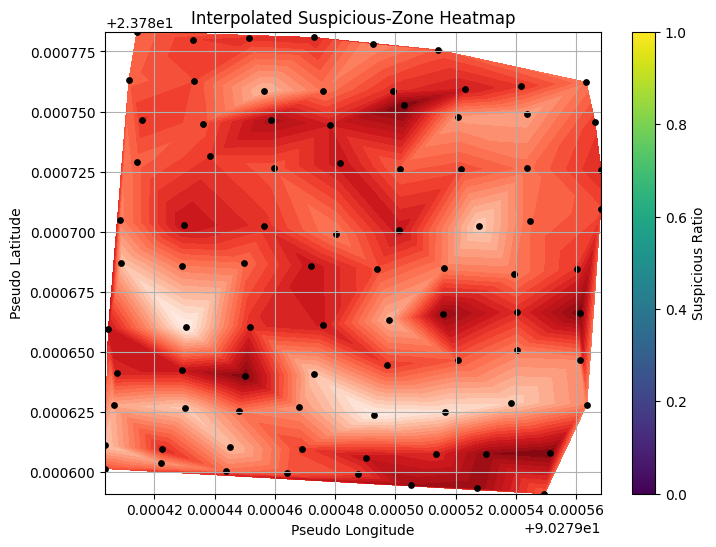

  0%|          | 0/86 [00:00<?, ?it/s]

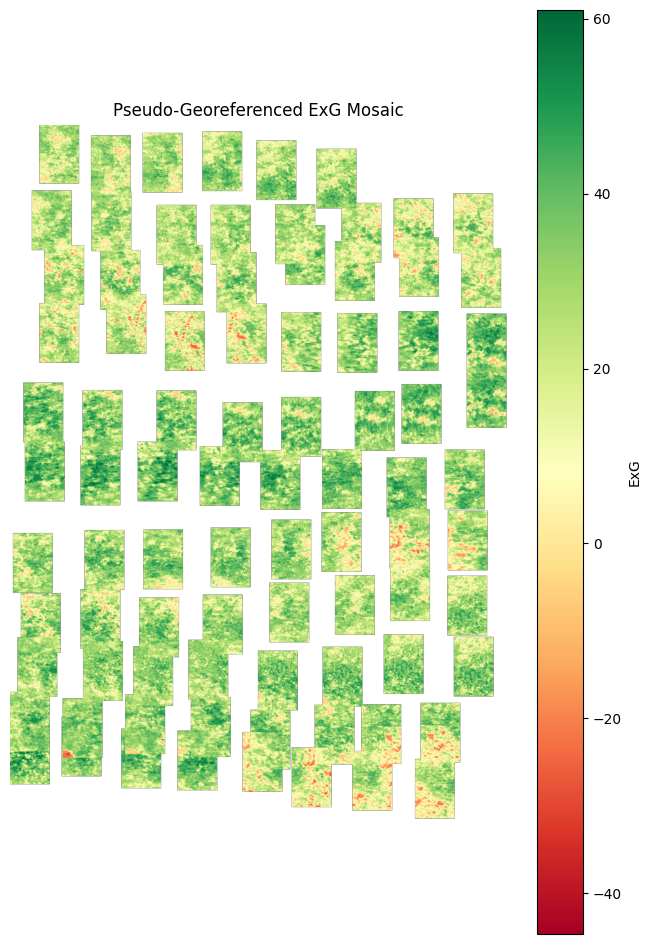

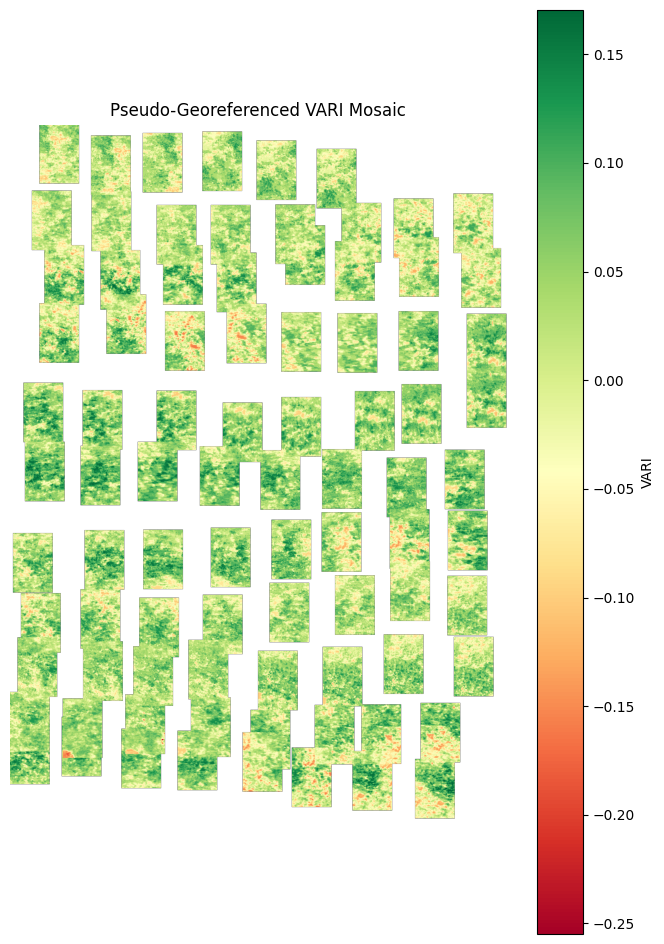

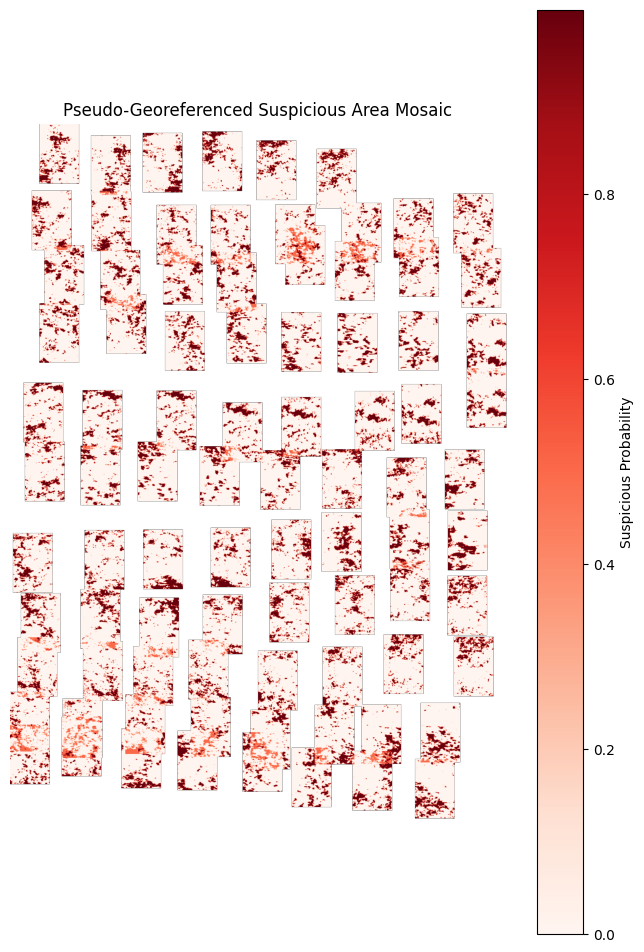

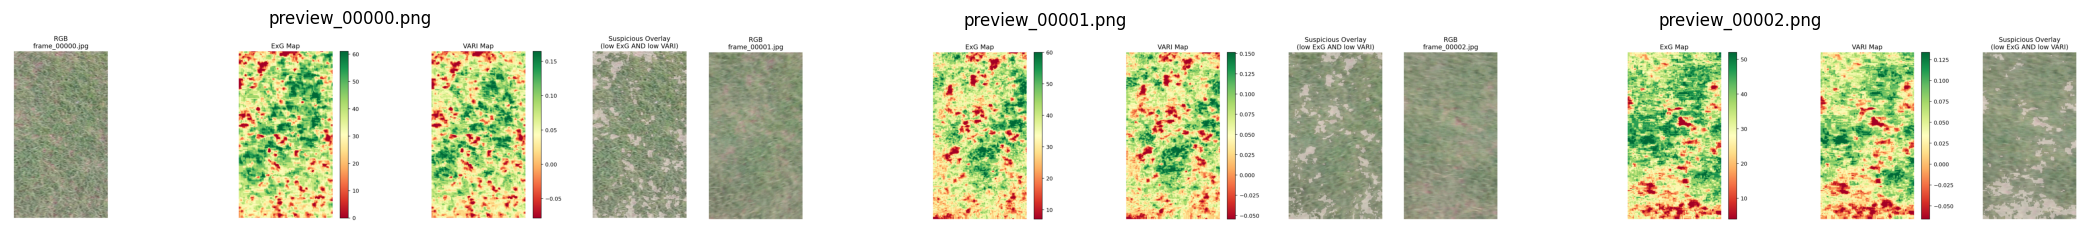


Done.
Synthetic GPS log: /content/drive/MyDrive/uav_project/synthetic_gps_log.csv
Frame metrics: /content/drive/MyDrive/uav_project/frame_level_metrics.csv
Frame previews folder: /content/drive/MyDrive/uav_project/frame_level_outputs
Area outputs folder: /content/drive/MyDrive/uav_project/area_level_outputs
                  metric      value
0             num_frames  86.000000
1       mean_of_mean_exg  26.292678
2      mean_of_mean_vari   0.027653
3   max_suspicious_ratio   0.182511
4  mean_suspicious_ratio   0.164270


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import cv2
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

VIDEO_PATH = Path("/content/drive/MyDrive/uav_project/drone_video.mp4")
BASE_DIR = Path("/content/drive/MyDrive/uav_project")
FRAME_DIR = BASE_DIR / "extracted_frames"
FRAME_PREVIEW_DIR = BASE_DIR / "frame_level_outputs"
AREA_DIR = BASE_DIR / "area_level_outputs"

FRAME_DIR.mkdir(parents=True, exist_ok=True)
FRAME_PREVIEW_DIR.mkdir(parents=True, exist_ok=True)
AREA_DIR.mkdir(parents=True, exist_ok=True)

print("Video exists:", VIDEO_PATH.exists())

cap = cv2.VideoCapture(str(VIDEO_PATH))
print("cap opened:", cap.isOpened())

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if not cap.isOpened():
    raise ValueError("Video could not be opened. Check the file path.")

if fps is None or fps <= 0:
    print("FPS could not be read. Setting fallback FPS = 30")
    fps = 30.0

duration = frame_count / fps if frame_count > 0 else 0
print("Final FPS:", fps)
print("Frame count:", frame_count)
print("Duration (s):", duration)
cap.release()

interval_sec = 0.2
cap = cv2.VideoCapture(str(VIDEO_PATH))
step = max(1, int(round(fps * interval_sec)))

saved = 0
idx = 0
frame_rows = []

while True:
    ret, frame = cap.read()
    if not ret:
        break

    if idx % step == 0:
        frame_name = f"frame_{saved:05d}.jpg"
        frame_path = FRAME_DIR / frame_name
        cv2.imwrite(str(frame_path), frame)

        timestamp_sec = idx / fps
        frame_rows.append({
            "frame_idx_video": idx,
            "frame_id": saved,
            "frame_name": frame_name,
            "frame_path": str(frame_path),
            "timestamp_sec": timestamp_sec
        })
        saved += 1

    idx += 1

cap.release()

frames_df = pd.DataFrame(frame_rows)
print("Saved frames:", len(frames_df))

np.random.seed(42)

n = len(frames_df)
start_lat = 23.780600
start_lon = 90.279400
row_len = 8
n_rows = math.ceil(n / row_len)

base_d_lat = 0.000018
base_d_lon = 0.000022

rows = []
k = 0
lat_drift = 0.0
lon_drift = 0.0

for r in range(n_rows):
    col_order = list(range(row_len)) if r % 2 == 0 else list(range(row_len - 1, -1, -1))

    for c in col_order:
        if k >= n:
            break

        t = frames_df.loc[k, "timestamp_sec"]

        lat_base = start_lat + r * base_d_lat
        lon_base = start_lon + c * base_d_lon

        lat_drift += np.random.normal(0, 0.0000015)
        lon_drift += np.random.normal(0, 0.0000015)

        wobble_lat = 0.0000025 * np.sin(2 * np.pi * k / 11.0)
        wobble_lon = 0.0000020 * np.cos(2 * np.pi * k / 13.0)

        gps_noise_lat = np.random.normal(0, 0.0000012)
        gps_noise_lon = np.random.normal(0, 0.0000012)

        lat = lat_base + lat_drift + wobble_lat + gps_noise_lat
        lon = lon_base + lon_drift + wobble_lon + gps_noise_lon

        altitude_m = 28 + 1.2 * np.sin(2 * np.pi * k / 9.0) + np.random.normal(0, 0.25)
        heading_deg = (90 if r % 2 == 0 else 270) + 5 * np.sin(2 * np.pi * k / 7.0) + np.random.normal(0, 1.2)
        speed_mps = 2.5 + 0.3 * np.sin(2 * np.pi * k / 8.0) + np.random.normal(0, 0.08)

        rows.append({
            "frame_id": int(frames_df.loc[k, "frame_id"]),
            "frame_name": frames_df.loc[k, "frame_name"],
            "frame_path": frames_df.loc[k, "frame_path"],
            "timestamp_sec": float(t),
            "lat": lat,
            "lon": lon,
            "altitude_m": altitude_m,
            "heading_deg": heading_deg,
            "speed_mps": speed_mps,
            "survey_row": r,
            "survey_col": c
        })
        k += 1

gps_df = pd.DataFrame(rows)
gps_csv_path = BASE_DIR / "synthetic_gps_log.csv"
gps_df.to_csv(gps_csv_path, index=False)
print("Synthetic GPS log saved to:", gps_csv_path)

def compute_exg_vari(frame_path):
    img = np.array(Image.open(frame_path).convert("RGB")).astype(np.float32)
    R = img[:, :, 0]
    G = img[:, :, 1]
    B = img[:, :, 2]
    exg = 2 * G - R - B
    vari = (G - R) / (G + R - B + 1e-6)
    return img, exg, vari

def robust_stats(x, low_q=2, high_q=98):
    lo = np.percentile(x, low_q)
    hi = np.percentile(x, high_q)
    x_clip = np.clip(x, lo, hi)
    return {
        "mean": float(np.mean(x_clip)),
        "std": float(np.std(x_clip)),
        "min_clip": float(np.min(x_clip)),
        "max_clip": float(np.max(x_clip)),
        "lo": float(lo),
        "hi": float(hi)
    }

def clip_map(x, low_q=2, high_q=98):
    lo = np.percentile(x, low_q)
    hi = np.percentile(x, high_q)
    return np.clip(x, lo, hi)

feature_rows = []

for _, row in tqdm(gps_df.iterrows(), total=len(gps_df)):
    img, exg, vari = compute_exg_vari(row["frame_path"])

    exg_stats = robust_stats(exg)
    vari_stats = robust_stats(vari)

    exg_low_thresh = np.percentile(exg, 20)
    vari_low_thresh = np.percentile(vari, 20)

    low_exg_mask = (exg < exg_low_thresh).astype(np.uint8)
    low_vari_mask = (vari < vari_low_thresh).astype(np.uint8)

    kernel = np.ones((5, 5), np.uint8)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_OPEN, kernel)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_CLOSE, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_OPEN, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_CLOSE, kernel)

    suspicious_mask = (low_exg_mask & low_vari_mask).astype(bool)

    low_exg_ratio = float(np.mean(low_exg_mask))
    low_vari_ratio = float(np.mean(low_vari_mask))
    suspicious_ratio = float(np.mean(suspicious_mask))

    feature_rows.append({
        "frame_id": row["frame_id"],
        "frame_name": row["frame_name"],
        "frame_path": row["frame_path"],
        "timestamp_sec": row["timestamp_sec"],
        "lat": row["lat"],
        "lon": row["lon"],
        "altitude_m": row["altitude_m"],
        "heading_deg": row["heading_deg"],
        "speed_mps": row["speed_mps"],
        "survey_row": row["survey_row"],
        "survey_col": row["survey_col"],
        "mean_exg": exg_stats["mean"],
        "std_exg": exg_stats["std"],
        "mean_vari": vari_stats["mean"],
        "std_vari": vari_stats["std"],
        "low_exg_ratio": low_exg_ratio,
        "low_vari_ratio": low_vari_ratio,
        "suspicious_ratio": suspicious_ratio
    })

index_df = pd.DataFrame(feature_rows)
metrics_csv_path = BASE_DIR / "frame_level_metrics.csv"
index_df.to_csv(metrics_csv_path, index=False)
print("Frame-level metrics saved to:", metrics_csv_path)

for _, row in tqdm(index_df.iterrows(), total=len(index_df)):
    img, exg, vari = compute_exg_vari(row["frame_path"])

    exg_map = clip_map(exg)
    vari_map = clip_map(vari)

    exg_low_thresh = np.percentile(exg, 20)
    vari_low_thresh = np.percentile(vari, 20)

    low_exg_mask = (exg < exg_low_thresh).astype(np.uint8)
    low_vari_mask = (vari < vari_low_thresh).astype(np.uint8)

    kernel = np.ones((5, 5), np.uint8)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_OPEN, kernel)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_CLOSE, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_OPEN, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_CLOSE, kernel)

    suspicious_mask = (low_exg_mask & low_vari_mask).astype(bool)

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(img.astype(np.uint8))
    axes[0].set_title(f"RGB\n{row['frame_name']}")
    axes[0].axis("off")

    im1 = axes[1].imshow(exg_map, cmap="RdYlGn")
    axes[1].set_title("ExG Map")
    axes[1].axis("off")
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

    im2 = axes[2].imshow(vari_map, cmap="RdYlGn")
    axes[2].set_title("VARI Map")
    axes[2].axis("off")
    plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    axes[3].imshow(img.astype(np.uint8))
    axes[3].imshow(np.where(suspicious_mask, 1.0, np.nan), cmap="Reds", alpha=0.45)
    axes[3].set_title("Suspicious Overlay\n(low ExG AND low VARI)")
    axes[3].axis("off")

    plt.tight_layout()
    out_path = FRAME_PREVIEW_DIR / f"preview_{int(row['frame_id']):05d}.png"
    plt.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.close()

preview_files = sorted(FRAME_PREVIEW_DIR.glob("*.png"))
print("Saved frame previews:", len(preview_files))

plt.figure(figsize=(8, 6))
plt.plot(gps_df["lon"], gps_df["lat"], "-o", markersize=3)
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Synthetic Drone Flight Path")
plt.grid(True)
plt.savefig(AREA_DIR / "synthetic_flight_path.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
sc = plt.scatter(index_df["lon"], index_df["lat"], c=index_df["mean_exg"], cmap="RdYlGn", s=260, edgecolors="black")
plt.colorbar(sc, label="Mean ExG")
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Area-Level Mean ExG Frame Map")
plt.grid(True)
plt.savefig(AREA_DIR / "area_mean_exg_scatter.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
sc = plt.scatter(index_df["lon"], index_df["lat"], c=index_df["mean_vari"], cmap="RdYlGn", s=260, edgecolors="black")
plt.colorbar(sc, label="Mean VARI")
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Area-Level Mean VARI Frame Map")
plt.grid(True)
plt.savefig(AREA_DIR / "area_mean_vari_scatter.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
sc = plt.scatter(index_df["lon"], index_df["lat"], c=index_df["suspicious_ratio"], cmap="Reds", s=260, edgecolors="black")
plt.colorbar(sc, label="Suspicious Ratio")
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Area-Level Suspicious Region Map")
plt.grid(True)
plt.savefig(AREA_DIR / "area_suspicious_ratio_scatter.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.tricontourf(index_df["lon"], index_df["lat"], index_df["mean_vari"], levels=20, cmap="RdYlGn")
plt.scatter(index_df["lon"], index_df["lat"], c="black", s=15)
plt.colorbar(label="Mean VARI")
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Interpolated Area-Level VARI Heatmap")
plt.grid(True)
plt.savefig(AREA_DIR / "area_vari_interpolated.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.tricontourf(index_df["lon"], index_df["lat"], index_df["suspicious_ratio"], levels=20, cmap="Reds")
plt.scatter(index_df["lon"], index_df["lat"], c="black", s=15)
plt.colorbar(label="Suspicious Ratio")
plt.xlabel("Pseudo Longitude")
plt.ylabel("Pseudo Latitude")
plt.title("Interpolated Suspicious-Zone Heatmap")
plt.grid(True)
plt.savefig(AREA_DIR / "area_suspicious_interpolated.png", dpi=220, bbox_inches="tight")
plt.show()

tile_h = 120
tile_w = 80

lats = index_df["lat"].values
lons = index_df["lon"].values

lat_min, lat_max = lats.min(), lats.max()
lon_min, lon_max = lons.min(), lons.max()

canvas_h = 1400
canvas_w = 1000

sum_exg = np.zeros((canvas_h, canvas_w), dtype=np.float32)
sum_vari = np.zeros((canvas_h, canvas_w), dtype=np.float32)
sum_susp = np.zeros((canvas_h, canvas_w), dtype=np.float32)
count_canvas = np.zeros((canvas_h, canvas_w), dtype=np.float32)

for _, row in tqdm(index_df.iterrows(), total=len(index_df)):
    _, exg, vari = compute_exg_vari(row["frame_path"])

    exg_lo, exg_hi = np.percentile(exg, 2), np.percentile(exg, 98)
    vari_lo, vari_hi = np.percentile(vari, 2), np.percentile(vari, 98)

    exg_small = cv2.resize(np.clip(exg, exg_lo, exg_hi), (tile_w, tile_h), interpolation=cv2.INTER_AREA)
    vari_small = cv2.resize(np.clip(vari, vari_lo, vari_hi), (tile_w, tile_h), interpolation=cv2.INTER_AREA)

    exg_low_thresh = np.percentile(exg, 20)
    vari_low_thresh = np.percentile(vari, 20)

    low_exg_mask = (exg < exg_low_thresh).astype(np.uint8)
    low_vari_mask = (vari < vari_low_thresh).astype(np.uint8)

    kernel = np.ones((5, 5), np.uint8)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_OPEN, kernel)
    low_exg_mask = cv2.morphologyEx(low_exg_mask, cv2.MORPH_CLOSE, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_OPEN, kernel)
    low_vari_mask = cv2.morphologyEx(low_vari_mask, cv2.MORPH_CLOSE, kernel)

    suspicious = (low_exg_mask & low_vari_mask).astype(np.float32)
    suspicious_small = cv2.resize(suspicious, (tile_w, tile_h), interpolation=cv2.INTER_AREA)

    x = int((row["lon"] - lon_min) / (lon_max - lon_min + 1e-9) * (canvas_w - tile_w))
    y = int((lat_max - row["lat"]) / (lat_max - lat_min + 1e-9) * (canvas_h - tile_h))

    sum_exg[y:y+tile_h, x:x+tile_w] += exg_small
    sum_vari[y:y+tile_h, x:x+tile_w] += vari_small
    sum_susp[y:y+tile_h, x:x+tile_w] += suspicious_small
    count_canvas[y:y+tile_h, x:x+tile_w] += 1

mosaic_exg = sum_exg / (count_canvas + 1e-6)
mosaic_vari = sum_vari / (count_canvas + 1e-6)
mosaic_susp = sum_susp / (count_canvas + 1e-6)

mosaic_exg[count_canvas == 0] = np.nan
mosaic_vari[count_canvas == 0] = np.nan
mosaic_susp[count_canvas == 0] = np.nan

plt.figure(figsize=(8, 12))
plt.imshow(mosaic_exg, cmap="RdYlGn")
plt.colorbar(label="ExG")
plt.title("Pseudo-Georeferenced ExG Mosaic")
plt.axis("off")
plt.savefig(AREA_DIR / "mosaic_exg.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 12))
plt.imshow(mosaic_vari, cmap="RdYlGn")
plt.colorbar(label="VARI")
plt.title("Pseudo-Georeferenced VARI Mosaic")
plt.axis("off")
plt.savefig(AREA_DIR / "mosaic_vari.png", dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 12))
plt.imshow(mosaic_susp, cmap="Reds")
plt.colorbar(label="Suspicious Probability")
plt.title("Pseudo-Georeferenced Suspicious Area Mosaic")
plt.axis("off")
plt.savefig(AREA_DIR / "mosaic_suspicious.png", dpi=220, bbox_inches="tight")
plt.show()

n_show = min(3, len(preview_files))
fig, axes = plt.subplots(1, n_show, figsize=(7 * n_show, 6))
if n_show == 1:
    axes = [axes]

for ax, f in zip(axes, preview_files[:n_show]):
    img_prev = np.array(Image.open(f))
    ax.imshow(img_prev)
    ax.set_title(f.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

summary_df = pd.DataFrame({
    "metric": [
        "num_frames",
        "mean_of_mean_exg",
        "mean_of_mean_vari",
        "max_suspicious_ratio",
        "mean_suspicious_ratio"
    ],
    "value": [
        len(index_df),
        index_df["mean_exg"].mean(),
        index_df["mean_vari"].mean(),
        index_df["suspicious_ratio"].max(),
        index_df["suspicious_ratio"].mean()
    ]
})

summary_path = AREA_DIR / "area_summary_stats.csv"
summary_df.to_csv(summary_path, index=False)

print("\nDone.")
print("Synthetic GPS log:", gps_csv_path)
print("Frame metrics:", metrics_csv_path)
print("Frame previews folder:", FRAME_PREVIEW_DIR)
print("Area outputs folder:", AREA_DIR)
print(summary_df)